In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
df.describe()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual s

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [5]:

df["wine_quality"] = (df["quality"] >= 6).astype(int)

df["wine_quality"].value_counts()


,count
wine_quality,
1,855
0,744


In [6]:

X = df.drop(columns=["quality", "wine_quality"])

y = df["wine_quality"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (1599, 11)
Target shape: (1599,)


In [7]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 1279
Testing samples: 320


In [8]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)


Training data scaled: (1279, 11)
Testing data scaled: (320, 11)


In [9]:

from sklearn.linear_model import LogisticRegression

# Initialize the model
lr_model = LogisticRegression(random_state=42)

# Train the model
lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [10]:

y_pred_lr = lr_model.predict(X_test_scaled)

print("Predictions generated successfully!")
print("First 10 predictions:", y_pred_lr[:10])


Predictions generated successfully!
First 10 predictions: [0 1 0 0 1 1 0 0 0 1]


In [11]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)

print("Logistic Regression Evaluation")
print("----------------------------")
print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score:", round(lr_f1, 4))


Logistic Regression Evaluation
----------------------------
Accuracy : 0.7406
Precision: 0.7683
Recall   : 0.7368
F1 Score: 0.7522


In [12]:

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")


Decision Tree trained successfully!


In [13]:

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree predictions generated!")
print("First 10 predictions:", y_pred_dt[:10])


Decision Tree predictions generated!
First 10 predictions: [1 0 1 1 1 1 0 0 1 1]


In [14]:

dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)

print("Decision Tree Evaluation")
print("-----------------------")
print("Accuracy :", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1 Score:", round(dt_f1, 4))


Decision Tree Evaluation
-----------------------
Accuracy : 0.7531
Precision: 0.7644
Recall   : 0.7778
F1 Score: 0.771


In [15]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [16]:

# ==========================================
# TRAIN AND EVALUATE REMAINING MODELS
# ==========================================

# 1. Random Forest Predictions & Evaluation
y_pred_rf = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

# 2. K-Nearest Neighbors
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn)
knn_recall = recall_score(y_test, y_pred_knn)
knn_f1 = f1_score(y_test, y_pred_knn)

# 3. Support Vector Machine
svm_model = SVC(kernel="rbf", random_state=42)
svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall = recall_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)

print("All remaining models trained and evaluated!")


All remaining models trained and evaluated!


In [17]:

# ==========================================
# MODEL COMPARISON TABLE
# ==========================================

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVM"
    ],
    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy,
        knn_accuracy,
        svm_accuracy
    ],
    "Precision": [
        lr_precision,
        dt_precision,
        rf_precision,
        knn_precision,
        svm_precision
    ],
    "Recall": [
        lr_recall,
        dt_recall,
        rf_recall,
        knn_recall,
        svm_recall
    ],
    "F1 Score": [
        lr_f1,
        dt_f1,
        rf_f1,
        knn_f1,
        svm_f1
    ]
})

results = results.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

results.round(4)


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.8062,0.8344,0.7953,0.8144
1,Decision Tree,0.7531,0.7644,0.7778,0.7710
2,SVM,0.7625,0.8146,0.7193,0.7640
3,KNN,0.7406,0.7588,0.7544,0.7566
4,Logistic Regression,0.7406,0.7683,0.7368,0.7522


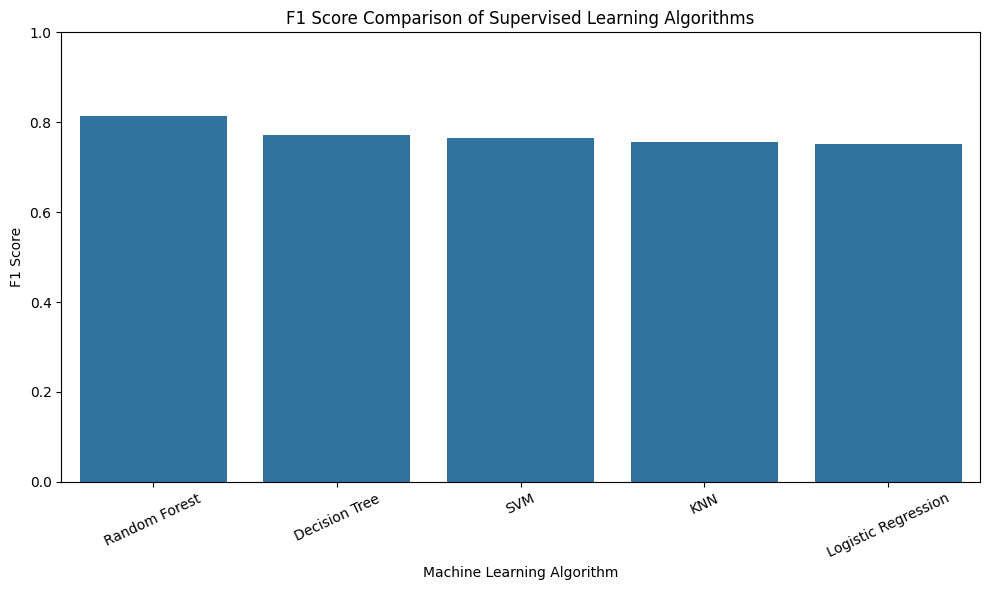

In [18]:

# ==========================================
# MODEL COMPARISON VISUALIZATION
# ==========================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x="Model",
    y="F1 Score"
)

plt.title("F1 Score Comparison of Supervised Learning Algorithms")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("F1 Score")
plt.xticks(rotation=25)
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig("model_comparison.png", dpi=300)
plt.show()


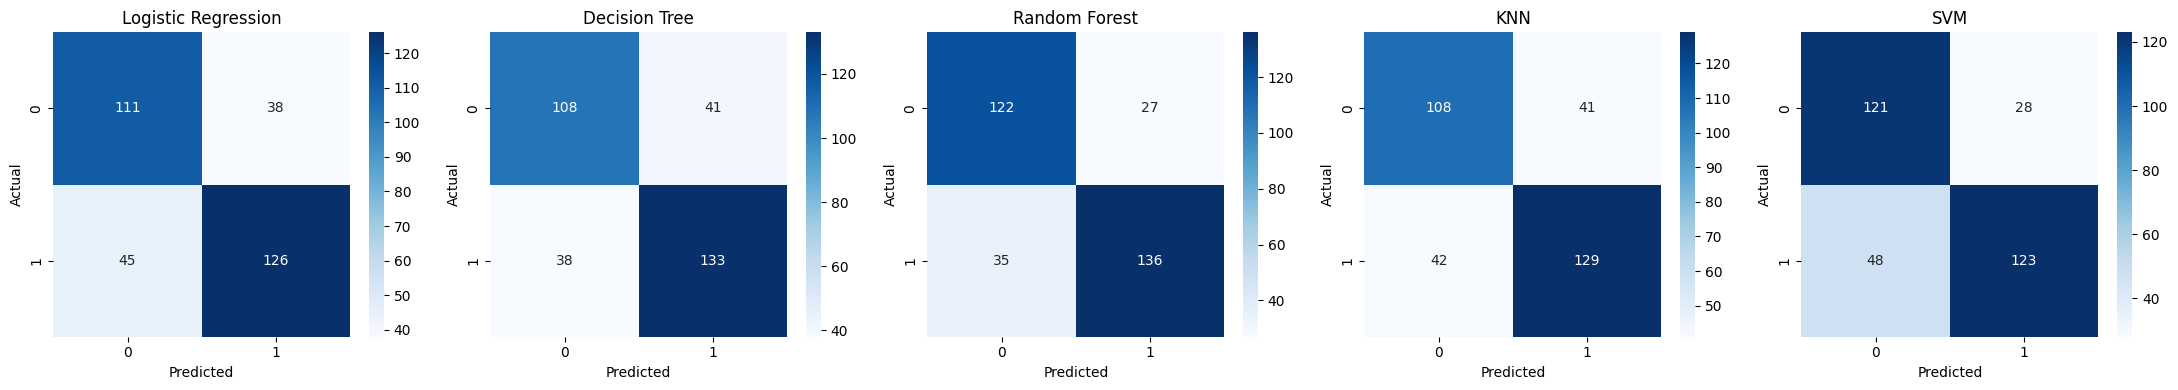

In [19]:

# ==========================================
# CONFUSION MATRICES
# ==========================================

predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "KNN": y_pred_knn,
    "SVM": y_pred_svm
}

fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()



# Comparative Study of Supervised Learning Algorithms

## Project Overview
This project compares five supervised machine learning classification algorithms on the Wine Quality dataset. The objective is to understand how different algorithms perform on the same dataset using identical training and testing conditions.

## Dataset
- Dataset: Wine Quality (Red Wine)
- Source: UCI Machine Learning Repository
- Total samples: 1599
- Features: 11 physicochemical properties
- Original target: Wine quality score
- Classification target:
  - Quality >= 6: Good Wine (1)
  - Quality < 6: Bad Wine (0)

## Algorithms Implemented
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. K-Nearest Neighbors (KNN)
5. Support Vector Machine (SVM)

## Methodology
- Dataset loaded using Pandas.
- Target variable converted into binary classification.
- Data split into 80% training and 20% testing.
- Stratified train-test split with random_state=42.
- StandardScaler applied for Logistic Regression, KNN, and SVM.
- Decision Tree and Random Forest trained on original features.
- All models evaluated on the same test set.

## Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score

## Results
The following confusion matrices were obtained on the test set:

| Model | TN | FP | FN | TP |
|---|---:|---:|---:|---:|
| Logistic Regression | 111 | 38 | 45 | 126 |
| Decision Tree | 108 | 41 | 38 | 133 |
| Random Forest | 122 | 27 | 35 | 136 |
| KNN | 108 | 41 | 42 | 129 |
| SVM | 121 | 28 | 48 | 123 |

Random Forest achieved the highest number of correct predictions (258 out of 320).

## Analysis
Random Forest performed strongly because it combines multiple decision trees, reducing variance and capturing nonlinear relationships among wine properties. It also handles interactions between features effectively.

Decision Tree captured nonlinear relationships but may have overfitted the training data because a single tree is sensitive to variations in the dataset.

Logistic Regression provides a linear decision boundary, which may limit its ability to capture complex relationships between wine properties and quality.

KNN depends on distance calculations and can struggle when the dataset contains overlapping classes or noisy features.

SVM can capture nonlinear decision boundaries using the RBF kernel, but its performance depends on parameter selection and the distribution of the data.

## Conclusion
This experiment demonstrates that different supervised learning algorithms behave differently on the same dataset. Random Forest showed the strongest overall classification performance in this experiment, while the other algorithms provided useful comparisons of linear, tree-based, distance-based, and kernel-based approaches.

## Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn
- Google Colab

## Author
Machine Learning Internship Project
